# SC452 – Processes on Networks
## Assignment 9: Network Resilience and Approximate One-Dimensional Reduction

This notebook contains:

* **Section I (Analytical)** – reference derivations for Q1, with a small numerical helper that draws the
  bifurcation diagram (the handwritten solution must still be submitted separately).
* **Section II (Numerical)** – full implementations, plots, tables, accuracy checks and observations for
  **Q2 (gene-regulatory dynamics)** and **Q3 (SIS dynamics)**.

No NetworkX / igraph / epidemic packages are used: the networks, the removal experiments and the dynamics
are written from scratch with `numpy`; ODEs are integrated with `scipy.integrate.solve_ivp`.

---
# Section I: Analytical (reference derivations)

Model: $\dot x_i = -(x_i-r_1)(x_i-r_2)(x_i-r_3) + D\sum_j A_{ij}x_j$, with $A$ symmetric, $k_i=\sum_j A_{ij}$,
$L(z)=\sum_i k_i z_i / \sum_i k_i$, $x_{\rm eff}=L(x)$. Write $P(x)=(x-r_1)(x-r_2)(x-r_3)$ and assume $r_1<r_2<r_3$.

### (a) One-dimensional reduction
Apply $L$ to both sides:
$$\dot x_{\rm eff} = -L\big(P(x)\big) + D\,L(Ax).$$
For the coupling term, using symmetry of $A$,
$$L(Ax)=\frac{\sum_i k_i\sum_j A_{ij}x_j}{\sum_i k_i}=\frac{\sum_j (Ak)_j\,x_j}{\sum_i k_i}.$$
If the node states are close to each other, $x_j\approx x_{\rm eff}$, then
$L(Ax)\approx x_{\rm eff}\,\frac{\sum_j (Ak)_j}{\sum_i k_i}=x_{\rm eff}\frac{\sum_i k_i^2}{\sum_i k_i}$.
For the self-dynamics we use the mean-field closure $L(P(x))\approx P(L(x))$. Hence
$$\boxed{\dot x_{\rm eff}=-(x_{\rm eff}-r_1)(x_{\rm eff}-r_2)(x_{\rm eff}-r_3)+D\beta\,x_{\rm eff},\qquad
\beta=\frac{\sum_i k_i^2}{\sum_i k_i}=\frac{\langle k^2\rangle}{\langle k\rangle}.}$$

### (b) Equilibria and saddle-node bifurcation, $q=D\beta$
Let $g(x)=-P(x)+qx$. Equilibria are the intersections of the cubic $y=P(x)$ with the line $y=qx$ through the
origin, so there are **one or three** real equilibria (two coincide exactly at a bifurcation).
Stability: $g'(x^*)=-P'(x^*)+q<0$ (stable) or $>0$ (unstable). Because the leading coefficient of $g$ is
negative, with three equilibria the outer two are stable and the middle one is unstable (bistability).

A saddle-node requires $g=0$ and $g'=0$:
$$P(x_c)=q_c x_c,\qquad P'(x_c)=q_c \;\Longrightarrow\; x_cP'(x_c)-P(x_c)=0 .$$
With $s_1=r_1+r_2+r_3$, $s_2=r_1r_2+r_1r_3+r_2r_3$, $s_3=r_1r_2r_3$, $P=x^3-s_1x^2+s_2x-s_3$ and
$$\boxed{2x_c^3-s_1x_c^2+s_3=0,\qquad q_c=\frac{P(x_c)}{x_c}=P'(x_c)=3x_c^2-2s_1x_c+s_2 .}$$
Equivalently, equilibria with $x\neq0$ lie on the curve $q(x)=P(x)/x$ and the folds are its turning points
$q'(x)=0$. The fold that bounds the positive branch is the root $x_c>0$ with $q_c>0$ (this exists e.g. when
all $r_i<0$: then $q(x)=P(x)/x>0$ on $x>0$, $q\to\infty$ at both ends, and $q_c=\min_{x>0}q(x)$).
For $q>q_c$ there are two positive equilibria (upper stable, lower unstable); for $q<q_c$ none.

### (c) Bifurcation diagram and damage
See the plot below (solid = stable, dashed = unstable). Starting on the stable positive branch, damage lowers
$\beta$ and hence $q=D\beta$; the state tracks the branch smoothly (decreasing) until $q=q_c$, where it
collides with the unstable branch and disappears. For $q<q_c$ the system **jumps abruptly** to the remaining
(lower, possibly negative) stable state – a discontinuous collapse (tipping point).

### (d) Random regular network
All degrees equal $k$, so $\beta=k^2N/(kN)=k$ and $q=Dk$. The critical coupling is
$$D_c=\frac{q_c}{k}.$$
Restoring $D$ (or $\beta$) back above $D_c$ does **not** necessarily return the system to the positive branch:
in the bistable window the lower state is still stable, so the system stays there (hysteresis). Recovery
requires either an additional perturbation pushing $x_{\rm eff}$ past the unstable middle branch, or raising
$q$ beyond the *other* fold where the lower branch itself disappears (if such a fold exists at positive $q$).

### (e) Assumptions and limitations
1. *Homogeneous-state assumption* $x_j\approx x_{\rm eff}$ (used in $L(Ax)\approx\beta L(x)$).
2. *Mean-field closure* $L(P(x))\approx P(L(x))$ (exact only for linear $P$ or identical states).

Degree heterogeneity produces heterogeneous node states (hubs receive much larger input than low-degree
nodes). Because $P$ is nonlinear, $L(P(x))\ne P(L(x))$ when the states are spread (Jensen-type error), and the
weighted average of $\sum_jA_{ij}x_j$ is not $\beta x_{\rm eff}$ when states correlate with degree. Near a
bifurcation, small errors in the effective equation shift the predicted tipping point, and a network may be
partially active (some nodes up, some down), a state the 1D model cannot represent.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import brentq
import time, warnings
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

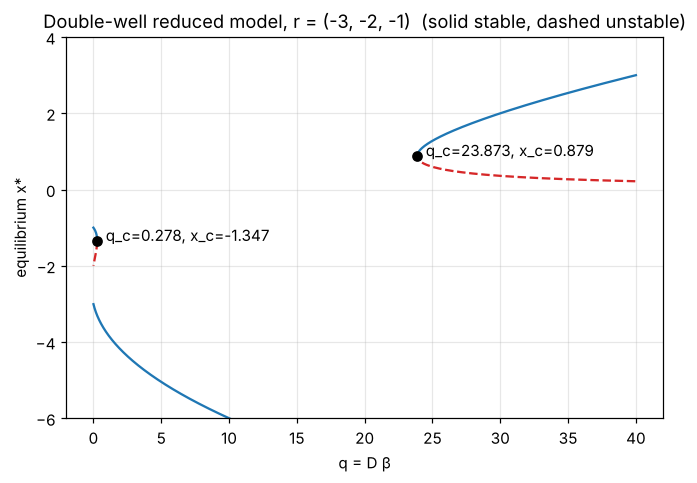

saddle-node: x_c = -2.53209, q_c = -0.15064
saddle-node: x_c = -1.34730, q_c = +0.27807
saddle-node: x_c = +0.87939, q_c = +23.87258


In [2]:
def double_well_bifurcation(r, q_range=(0, 40), ax=None):
    # Equilibria of dx/dt = -P(x) + q x, P(x)=(x-r1)(x-r2)(x-r3), traced via q(x) = P(x)/x
    r1, r2, r3 = sorted(r)
    s1, s3 = r1 + r2 + r3, r1 * r2 * r3
    P  = lambda x: (x - r1) * (x - r2) * (x - r3)
    dP = lambda x: (x - r2) * (x - r3) + (x - r1) * (x - r3) + (x - r1) * (x - r2)
    xc = np.roots([2, -s1, 0, s3]); xc = np.sort(xc[np.abs(xc.imag) < 1e-12].real)
    folds = [(x, P(x) / x) for x in xc if abs(x) > 1e-12]
    if ax is None: ax = plt.gca()
    for sgn in (-1, 1):
        x = sgn * np.logspace(-3, 1.5, 4000)
        q = P(x) / x
        stable = (-dP(x) + q) < 0
        ok = (q >= q_range[0]) & (q <= q_range[1])
        for mask, ls in ((stable & ok, "-"), (~stable & ok, "--")):
            xm = np.where(mask, x, np.nan)
            ax.plot(q, xm, ls, color="C0" if ls == "-" else "C3")
    for x, q in folds:
        if q_range[0] <= q <= q_range[1]:
            ax.plot(q, x, "ko"); ax.annotate(f"  q_c={q:.3f}, x_c={x:.3f}", (q, x))
    ax.set_xlabel("q = D β"); ax.set_ylabel("equilibrium x*")
    ax.set_title(f"Double-well reduced model, r = {tuple(r)}  (solid stable, dashed unstable)")
    return folds

# Illustrative choice of roots (the sheet keeps r1, r2, r3 symbolic) – change to your values
fig, ax = plt.subplots(figsize=(7, 4.5))
folds = double_well_bifurcation((-3, -2, -1), q_range=(0, 40), ax=ax)
ax.set_ylim(-6, 4); plt.show()
for x, q in folds: print(f"saddle-node: x_c = {x:+.5f}, q_c = {q:+.5f}")

---
# Section II: Numerical

## Common setup

**Networks** (N = 300, seed 42, written from scratch):
* Erdős–Rényi $G(N,p)$, $p=0.04$: each of the $\binom N2$ pairs is linked independently with probability $p$.
* Barabási–Albert, $m=6$: start from a complete graph on $m+1=7$ nodes; each new node attaches $m$ distinct
  edges to existing nodes chosen with probability $\propto k_j$ (sampling from the list of edge end-points).

**Removal** (nested sets, $f=0,0.05,\dots,0.80$; removed count $=\mathrm{round}(fN)$):
* *degree*: descending original degree, ties broken by smaller node index;
* *random*: permutation from `np.random.default_rng(24)`.

The surviving induced subgraph is used; degrees and $\beta=\sum k_i^2/\sum k_i$ are recomputed. Isolated
survivors are kept (weight 0 in $x_{\rm eff}$). If no edges remain, $\beta$ and $x_{\rm eff}$ are undefined
and the case is omitted.

**Numerical method.** `solve_ivp` with **LSODA** (automatic switching between non-stiff Adams and stiff
BDF methods – appropriate because the problems become slow/stiff near bifurcations), with the **analytic
Jacobian**, `rtol = 1e-10`, `atol = 1e-12`. These tolerances are far below the 1e-8 steady-state criterion,
so the residual check is not polluted by integration error.
**Stopping criterion:** integrate on $[0,300]$; if $\max_i|\dot x_i|\ge 10^{-8}$ at the end, continue from the
final state with the interval end doubled ($300\to600\to1200\to\cdots$) up to $t_{\max}=307{,}200$. Runs that
still miss the tolerance are flagged and reported.

In [3]:
N = 300
F_COARSE = np.round(np.arange(0, 0.80 + 1e-9, 0.05), 2)
F_FINE   = np.round(np.arange(0, 0.80 + 1e-9, 0.01), 2)
TOL, T_FIRST, T_MAX = 1e-8, 300.0, 300.0 * 2**10

def erdos_renyi(N, p, seed):
    rng = np.random.default_rng(seed)
    A = np.triu(rng.random((N, N)) < p, k=1).astype(float)
    return A + A.T

def barabasi_albert(N, m, seed):
    rng = np.random.default_rng(seed)
    A = np.zeros((N, N))
    m0 = m + 1
    A[:m0, :m0] = 1.0; np.fill_diagonal(A, 0.0)
    ends = [v for i in range(m0) for j in range(i + 1, m0) for v in (i, j)]   # degree-weighted list
    for new in range(m0, N):
        targets = set()
        while len(targets) < m:
            targets.add(ends[rng.integers(len(ends))])
        for t in targets:
            A[new, t] = A[t, new] = 1.0
            ends += [new, t]
    return A

NETS = {"ER": erdos_renyi(N, 0.04, 42), "BA": barabasi_albert(N, 6, 42)}

def removal_order(A, strategy):
    k = A.sum(1)
    if strategy == "degree":
        return np.lexsort((np.arange(len(k)), -k))      # primary: -degree, secondary: index
    return np.random.default_rng(24).permutation(len(k))

def damaged(A, order, f):
    n_rem = int(round(f * A.shape[0]))
    keep = np.sort(order[n_rem:])
    return A[np.ix_(keep, keep)]

def beta_of(A):
    k = A.sum(1)
    return np.nan if k.sum() == 0 else (k**2).sum() / k.sum()

def x_eff(A, x):
    k = A.sum(1)
    return np.nan if k.sum() == 0 else k @ x / k.sum()

for name, A in NETS.items():
    k = A.sum(1)
    assert np.allclose(A, A.T) and np.all(np.diag(A) == 0) and set(np.unique(A)) <= {0.0, 1.0}
    print(f"{name}: N={N}, edges={int(A.sum()/2)}, <k>={k.mean():.3f}, k_min={k.min():.0f}, "
          f"k_max={k.max():.0f}, beta={beta_of(A):.3f}, Lambda_max={np.linalg.eigvalsh(A)[-1]:.3f}")

ER: N=300, edges=1787, <k>=11.913, k_min=4, k_max=24, beta=12.932, Lambda_max=13.026
BA: N=300, edges=1779, <k>=11.860, k_min=6, k_max=71, beta=20.101, Lambda_max=19.900


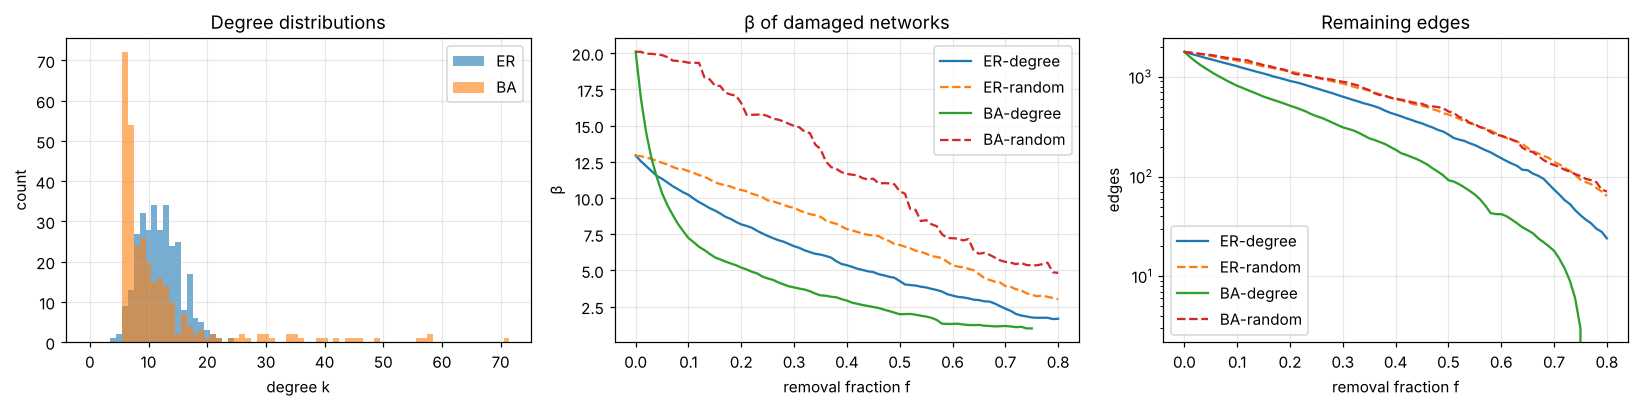

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for name, A in NETS.items():
    k = A.sum(1)
    axes[0].hist(k, bins=np.arange(k.max() + 2) - 0.5, alpha=0.6, label=name)
    for strat, ls in (("degree", "-"), ("random", "--")):
        order = removal_order(A, strat)
        b = [beta_of(damaged(A, order, f)) for f in F_FINE]
        axes[1].plot(F_FINE, b, ls, label=f"{name}-{strat}")
        e = [int(damaged(A, order, f).sum() / 2) for f in F_FINE]
        axes[2].plot(F_FINE, e, ls, label=f"{name}-{strat}")
axes[0].set(xlabel="degree k", ylabel="count", title="Degree distributions"); axes[0].legend()
axes[1].set(xlabel="removal fraction f", ylabel="β", title="β of damaged networks"); axes[1].legend()
axes[2].set(xlabel="removal fraction f", ylabel="edges", title="Remaining edges", yscale="log"); axes[2].legend()
plt.tight_layout(); plt.show()

In [5]:
def integrate_to_steady(rhs, jac, y0, keep_traj=False, t_first=T_FIRST, t_max=T_MAX, tol=TOL):
    # Integrate until max|dy/dt| < tol, doubling the end time; returns final state and diagnostics.
    y = np.asarray(y0, float).copy()
    t0, t1 = 0.0, t_first
    T, Y = [np.array([0.0])], [y[:, None]]
    while True:
        t_eval = np.linspace(t0, t1, 301) if keep_traj else None
        sol = solve_ivp(rhs, (t0, t1), y, method="LSODA", jac=jac,
                        rtol=1e-10, atol=1e-12, t_eval=t_eval)
        if not sol.success:
            raise RuntimeError(sol.message)
        y = sol.y[:, -1]
        if keep_traj: T.append(sol.t[1:]); Y.append(sol.y[:, 1:])
        res = np.max(np.abs(rhs(t1, y)))
        if res < tol or t1 >= t_max:
            break
        t0, t1 = t1, min(2 * t1, t_max)
    out = dict(y=y, t_end=t1, residual=res, converged=res < tol)
    if keep_traj: out["t"], out["Y"] = np.concatenate(T), np.hstack(Y)
    return out

---
## Q2. Gene-regulatory dynamics and loss of activity

$$\dot x_i=-x_i+D\sum_jA_{ij}\frac{x_j^2}{1+x_j^2},\qquad \dot z=-z+D\beta\frac{z^2}{1+z^2},\qquad D=0.25.$$

Jacobian of the full model: $J=-I+D\,A\,\mathrm{diag}\!\big(2x_j/(1+x_j^2)^2\big)$.

In [6]:
D_GENE = 0.25
X0_GENE = (0.01, 5.0)

def gene_full(A):
    rhs = lambda t, x: -x + D_GENE * (A @ (x**2 / (1 + x**2)))
    jac = lambda t, x: -np.eye(len(x)) + D_GENE * A * (2 * x / (1 + x**2)**2)[None, :]
    return rhs, jac

def gene_reduced(beta):
    rhs = lambda t, z: -z + D_GENE * beta * z**2 / (1 + z**2)
    jac = lambda t, z: np.array([[-1 + D_GENE * beta * 2 * z[0] / (1 + z[0]**2)**2]])
    return rhs, jac

def run_gene(A, x0, keep_traj=False):
    rhs, jac = gene_full(A)
    full = integrate_to_steady(rhs, jac, np.full(A.shape[0], x0), keep_traj)
    b = beta_of(A)
    rec = dict(beta=b, x_final=full["y"], xeff=x_eff(A, full["y"]), full_conv=full["converged"],
               full_res=full["residual"], full_T=full["t_end"], k=A.sum(1))
    if np.isnan(b):
        rec.update(z=np.nan, red_conv=True, red_res=0.0, red_T=0.0); return rec, full, None
    z0 = x_eff(A, np.full(A.shape[0], x0))            # = x0 for uniform initial conditions
    rr, rj = gene_reduced(b)
    red = integrate_to_steady(rr, rj, [z0], keep_traj)
    rec.update(z=red["y"][0], red_conv=red["converged"], red_res=red["residual"], red_T=red["t_end"])
    return rec, full, red

### Q2(a) Undamaged networks

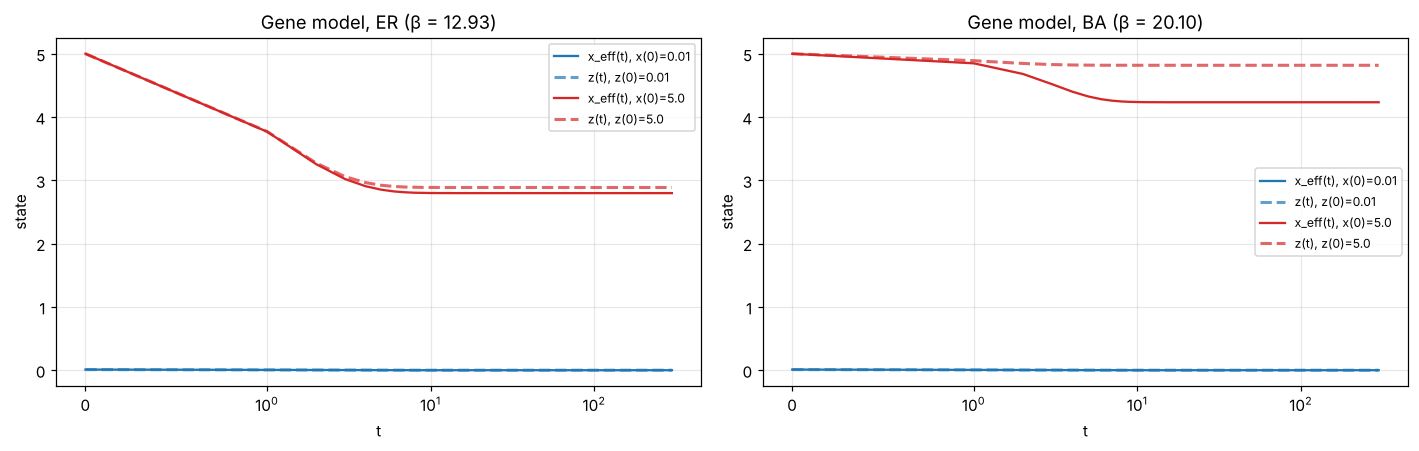

net     x0     beta      x_eff*          z*      |err|   T_full   res_full   T_red    res_red
ER    0.01   12.932   -0.000000   -0.000000  8.410e-21      300   2.27e-20     300   1.37e-20
ER    5.00   12.932    2.797840    2.886650  8.881e-02      300   8.88e-16     300   4.44e-16
BA    0.01   20.101   -0.000000   -0.000000  2.236e-21      300   1.68e-20     300   1.27e-20
BA    5.00   20.101    4.233614    4.817728  5.841e-01      300   1.78e-15     300   0.00e+00
Cases not meeting the 1e-8 tolerance: none


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
rows = []
for ax, (name, A) in zip(axes, NETS.items()):
    k = A.sum(1)
    for c, x0 in zip(("C0", "C3"), X0_GENE):
        rec, full, red = run_gene(A, x0, keep_traj=True)
        ax.plot(full["t"], k @ full["Y"] / k.sum(), color=c, label=f"x_eff(t), x(0)={x0}")
        ax.plot(red["t"], red["Y"][0], "--", color=c, lw=2, alpha=0.7, label=f"z(t), z(0)={x0}")
        rows.append((name, x0, rec["beta"], rec["xeff"], rec["z"], abs(rec["xeff"] - rec["z"]),
                     rec["full_T"], rec["full_res"], rec["red_T"], rec["red_res"]))
    ax.set_xscale("symlog", linthresh=1); ax.set_xlabel("t"); ax.set_ylabel("state")
    ax.set_title(f"Gene model, {name} (β = {beta_of(A):.2f})"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

print(f"{'net':4s}{'x0':>6s}{'beta':>9s}{'x_eff*':>12s}{'z*':>12s}{'|err|':>11s}"
      f"{'T_full':>9s}{'res_full':>11s}{'T_red':>8s}{'res_red':>11s}")
for r in rows:
    print(f"{r[0]:4s}{r[1]:6.2f}{r[2]:9.3f}{r[3]:12.6f}{r[4]:12.6f}{r[5]:11.3e}"
          f"{r[6]:9.0f}{r[7]:11.2e}{r[8]:8.0f}{r[9]:11.2e}")
bad = [r for r in rows if r[7] >= TOL or r[9] >= TOL]
print("Cases not meeting the 1e-8 tolerance:", bad if bad else "none")

**Observations (a).** Both networks have $\beta>8$ (ER 12.93, BA 20.10), so the reduced model is bistable.
From $x(0)=0.01$ the full networks and the reduced models all decay to the inactive state $0$ (always stable,
because the input $x^2/(1+x^2)$ has zero slope at 0). From $x(0)=5$ both converge to an active state:
ER $x^*_{\rm eff}=2.798$ vs $z^*=2.887$ ($E=0.089$); BA $x^*_{\rm eff}=4.234$ vs $z^*=4.818$ ($E=0.584$).
The reduced model overestimates the active level, much more on the heterogeneous BA network. All four
cases met the $10^{-8}$ residual within the initial interval $[0,300]$.

### Q2(b) Node-removal experiment

In [8]:
def gene_experiment(f_values):
    res = {}
    for name, A in NETS.items():
        for strat in ("degree", "random"):
            order = removal_order(A, strat)
            for f in f_values:
                As = damaged(A, order, f)
                for x0 in X0_GENE:
                    rec, _, _ = run_gene(As, x0)
                    res[(name, strat, f, x0)] = rec
    return res

t0 = time.time()
GENE = gene_experiment(F_COARSE)
print(f"{len(GENE)} full+reduced runs in {time.time()-t0:.1f} s")
nc = [(k, v["full_res"], v["red_res"]) for k, v in GENE.items() if not (v["full_conv"] and v["red_conv"])]
print("Runs not meeting the tolerance:", nc if nc else "none")

136 full+reduced runs in 1.9 s
Runs not meeting the tolerance: none


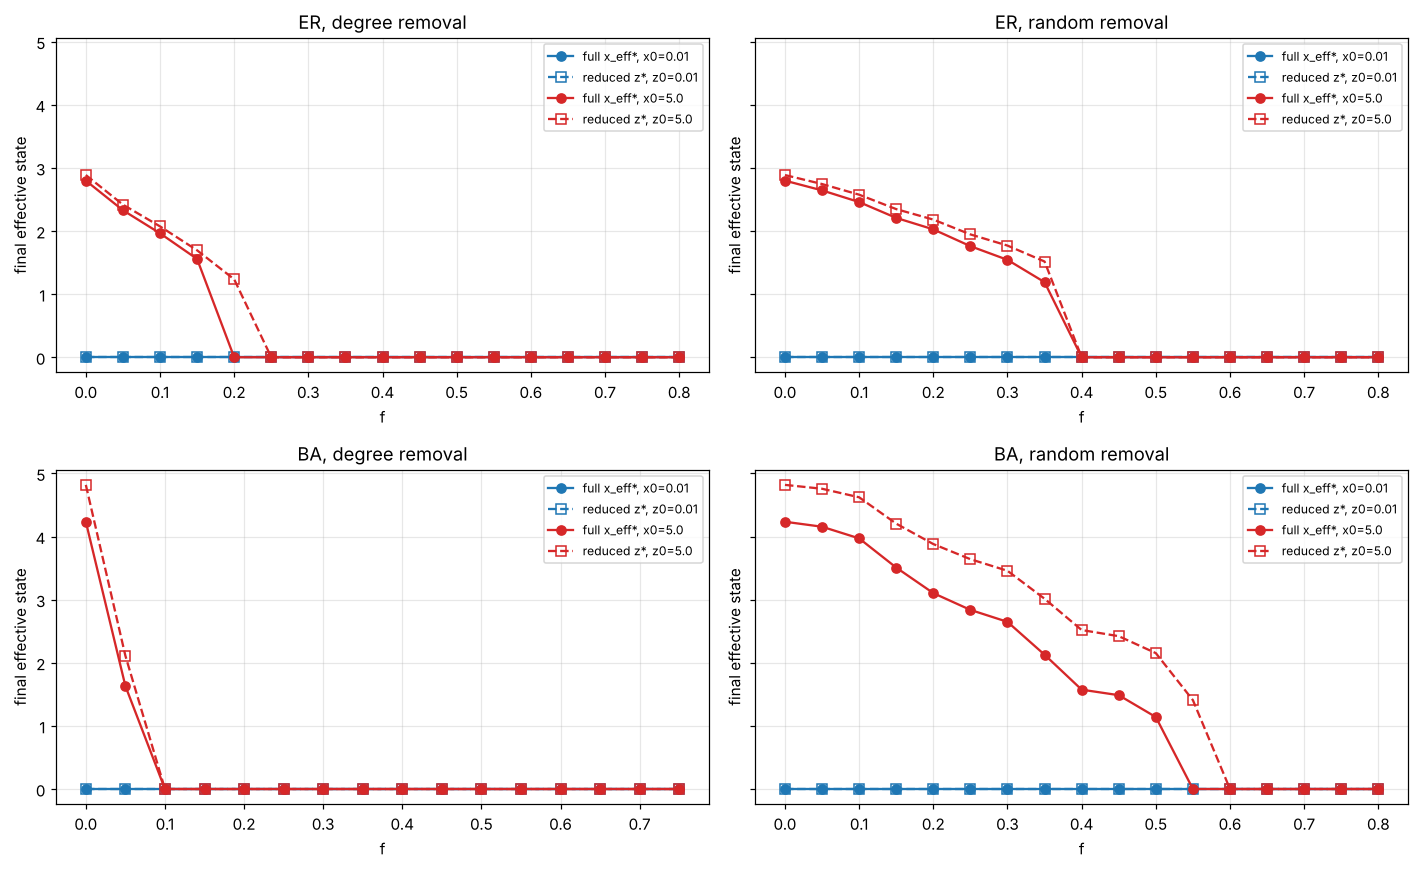

Intervals of f where the final state depends on the initial condition (|difference| > 1e-3):
  ER-degree full   : ['[0.00, 0.15]']
  ER-degree reduced: ['[0.00, 0.20]']
  ER-random full   : ['[0.00, 0.35]']
  ER-random reduced: ['[0.00, 0.35]']
  BA-degree full   : ['[0.00, 0.05]']
  BA-degree reduced: ['[0.00, 0.05]']
  BA-random full   : ['[0.00, 0.50]']
  BA-random reduced: ['[0.00, 0.55]']


In [9]:
def series(DB, name, strat, x0, key, fvals):
    return np.array([DB[(name, strat, f, x0)][key] for f in fvals])

fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharey=True)
for i, name in enumerate(NETS):
    for j, strat in enumerate(("degree", "random")):
        ax = axes[i, j]
        for c, x0 in zip(("C0", "C3"), X0_GENE):
            ax.plot(F_COARSE, series(GENE, name, strat, x0, "xeff", F_COARSE), "o-", color=c,
                    label=f"full x_eff*, x0={x0}")
            ax.plot(F_COARSE, series(GENE, name, strat, x0, "z", F_COARSE), "s--", color=c, mfc="none",
                    label=f"reduced z*, z0={x0}")
        ax.set_title(f"{name}, {strat} removal"); ax.set_xlabel("f"); ax.set_ylabel("final effective state")
        ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

def intervals(fvals, mask):
    out, start = [], None
    for f, m in zip(fvals, mask):
        if m and start is None: start = f
        if not m and start is not None: out.append((start, prev)); start = None
        prev = f
    if start is not None: out.append((start, prev))
    return [f"[{a:.2f}, {b:.2f}]" for a, b in out]

print("Intervals of f where the final state depends on the initial condition (|difference| > 1e-3):")
for name in NETS:
    for strat in ("degree", "random"):
        for key, lab in (("xeff", "full   "), ("z", "reduced")):
            lo = series(GENE, name, strat, 0.01, key, F_COARSE)
            hi = series(GENE, name, strat, 5.0, key, F_COARSE)
            print(f"  {name}-{strat:6s} {lab}: {intervals(F_COARSE, np.abs(hi - lo) > 1e-3)}")

**Observations (b).** From $x(0)=0.01$ every damaged network (and reduced model) ends inactive. From
$x(0)=5$ the active state survives up to a critical fraction and then disappears abruptly. The final state
therefore depends on the initial condition on the following intervals (coarse grid):

| case | full model | reduced model |
|---|---|---|
| ER – degree | $0\le f\le0.15$ | $0\le f\le0.20$ |
| ER – random | $0\le f\le0.35$ | $0\le f\le0.35$ |
| BA – degree | $0\le f\le0.05$ | $0\le f\le0.05$ |
| BA – random | $0\le f\le0.50$ | $0\le f\le0.55$ |

Degree-targeted removal lowers $\beta$ fastest and destroys bistability earliest, dramatically so for BA,
whose $\beta$ is dominated by hubs. Under random removal BA is the most robust network. The reduced model's
bistable window is never shorter than the full network's.

### Q2(c) Critical $\beta$ of the reduced model and comparison with the full networks

Positive equilibria satisfy $1=D\beta z/(1+z^2)$. We locate numerically (bisection on $\beta$, with
equilibria found by sign changes + Brent's method) the value at which the positive stable equilibrium
disappears. Analytically $z^2-D\beta z+1=0$ has real roots iff $D\beta\ge2$, i.e. $\beta_c=2/D=8$, $z_c=1$.

In [10]:
def positive_stable_eq(beta, zgrid=np.logspace(-6, 3, 20001)):
    g  = lambda z: -z + D_GENE * beta * z**2 / (1 + z**2)
    dg = lambda z: -1 + D_GENE * beta * 2 * z / (1 + z**2)**2
    v = g(zgrid); roots = []
    for a, b, va, vb in zip(zgrid[:-1], zgrid[1:], v[:-1], v[1:]):
        if va * vb < 0: roots.append(brentq(g, a, b, xtol=1e-14))
    st = [z for z in roots if dg(z) < 0]
    return max(st) if st else None

lo, hi = 0.0, 50.0                          # no positive state at lo, positive state at hi
for _ in range(60):
    mid = 0.5 * (lo + hi)
    if positive_stable_eq(mid) is None: lo = mid
    else: hi = mid
BETA_C = hi
print(f"Numerical critical beta = {BETA_C:.8f}   (analytic 2/D = {2/D_GENE})")
print(f"positive stable equilibrium just above beta_c: z = {positive_stable_eq(BETA_C*(1+1e-9)):.5f} (analytic z_c = 1)")

Numerical critical beta = 8.00000048   (analytic 2/D = 8.0)
positive stable equilibrium just above beta_c: z = 1.00035 (analytic z_c = 1)


case           f_c(0.05) f_c(0.01)  β before  β after  f_pred(β<8)
ER-degree           0.20      0.20     8.354    8.179         0.22
ER-random           0.40      0.36     8.705    8.455         0.40
BA-degree           0.10      0.07     9.510    8.844         0.09
BA-random           0.55      0.52    10.297    9.239         0.58


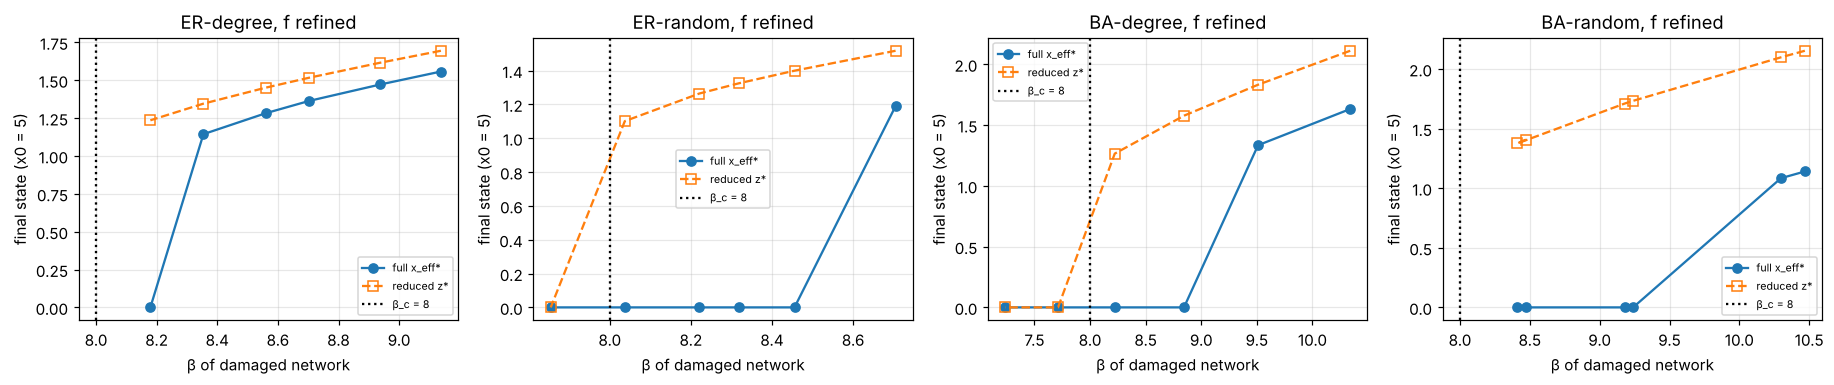

In [11]:
ACTIVE = 1e-3          # x_eff* above this from x(0)=5  ->  positive state present

def first_loss(fvals, values):
    for f, v in zip(fvals, values):
        if not (v > ACTIVE): return f
    return None

refine = {}
summary = []
for name, A in NETS.items():
    for strat in ("degree", "random"):
        order = removal_order(A, strat)
        xs = series(GENE, name, strat, 5.0, "xeff", F_COARSE)
        fc_coarse = first_loss(F_COARSE, xs)
        if fc_coarse is None:
            summary.append((name, strat, None, None, None, None, None)); continue
        f_fine = F_FINE[(F_FINE >= fc_coarse - 0.05 - 1e-9) & (F_FINE <= fc_coarse + 1e-9)]
        recs = [run_gene(damaged(A, order, f), 5.0)[0] for f in f_fine]
        refine[(name, strat)] = (f_fine, recs)
        xf = np.array([r["xeff"] for r in recs])
        fc = first_loss(f_fine, xf)
        b_before = recs[list(f_fine).index(fc) - 1]["beta"]
        b_after = recs[list(f_fine).index(fc)]["beta"]
        # reduced-model prediction: first fraction (0.01 grid) at which beta < beta_c
        betas = np.array([beta_of(damaged(A, order, f)) for f in F_FINE])
        f_pred = F_FINE[np.argmax(~(betas >= BETA_C))] if np.any(~(betas >= BETA_C)) else None
        summary.append((name, strat, fc_coarse, fc, b_before, b_after, f_pred))

print(f"{'case':14s}{'f_c(0.05)':>10s}{'f_c(0.01)':>10s}{'β before':>10s}{'β after':>9s}"
      f"{'f_pred(β<8)':>13s}")
for s in summary:
    if s[2] is None: print(f"{s[0]+'-'+s[1]:14s}  positive state never lost for f<=0.8"); continue
    print(f"{s[0]+'-'+s[1]:14s}{s[2]:10.2f}{s[3]:10.2f}{s[4]:10.3f}{s[5]:9.3f}{s[6]:13.2f}")

fig, axes = plt.subplots(1, len(refine), figsize=(4.2 * len(refine), 3.6))
for ax, ((name, strat), (ff, recs)) in zip(np.atleast_1d(axes), refine.items()):
    ax.plot([r["beta"] for r in recs], [r["xeff"] for r in recs], "o-", label="full x_eff*")
    ax.plot([r["beta"] for r in recs], [r["z"] for r in recs], "s--", mfc="none", label="reduced z*")
    ax.axvline(BETA_C, color="k", ls=":", label="β_c = 8")
    ax.set(xlabel="β of damaged network", ylabel="final state (x0 = 5)", title=f"{name}-{strat}, f refined")
    ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

**Observations (c).** The reduced model loses its positive stable equilibrium at $\beta_c=8.0000$ (bisection;
analytically $2/D=8$, with $z_c=1$). On the 0.01 grid the full networks lose the positive state at
$f_c=0.20$ (ER-degree), $0.36$ (ER-random), $0.07$ (BA-degree) and $0.52$ (BA-random). The reduced model
predicts $f=0.22,\,0.40,\,0.09,\,0.58$ (first fraction with $\beta<8$). **In every case the full network
collapses earlier**, while $\beta$ is still above 8: the collapse happens at $\beta\approx8.2$–$8.4$ (ER) and
$\approx8.8$–$9.2$ (BA). The error is larger for BA. Near the transition the node states are heterogeneous:
low-degree nodes receive too little input to stay active, and because the activation function is
nonlinear, $L(\text{input})$ is below $D\beta\,z^2/(1+z^2)$ (Jensen effect). So the network needs a larger
$\beta$ than the 1D model to remain active, and $\beta=8$ is an optimistic (late) estimate of the tipping point.

### Q2(d) Accuracy of the reduction: $E_{\rm abs}=|x^*_{\rm eff}-z^*|$

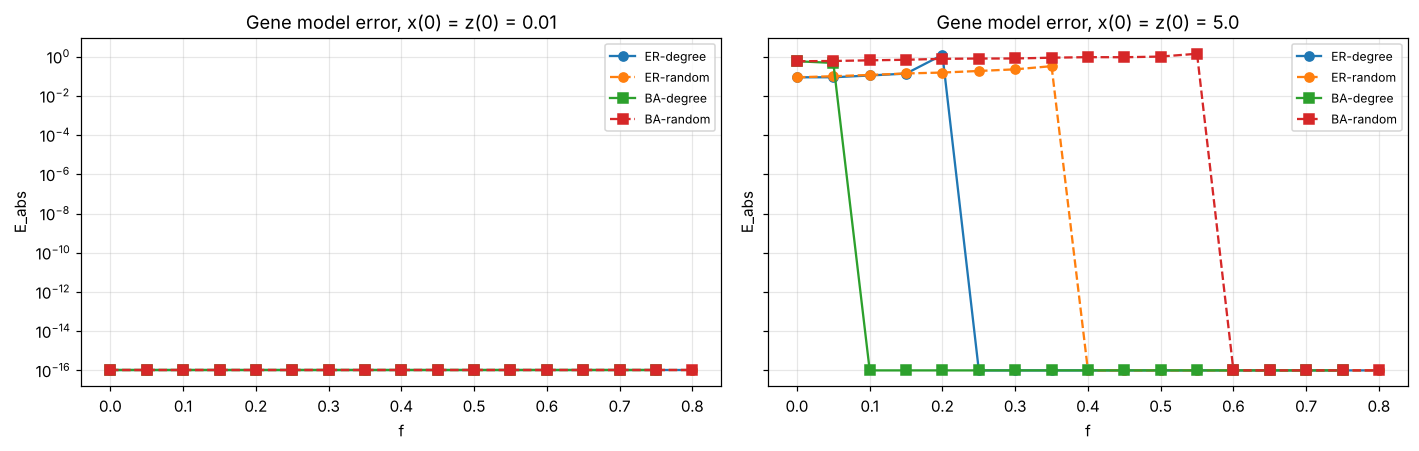

Largest error per case (x0 = 5):
  ER-degree: max E = 1.2352 at f = 0.20
  ER-random: max E = 0.3274 at f = 0.35
  BA-degree: max E = 0.5841 at f = 0.00
  BA-random: max E = 1.4074 at f = 0.55


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, x0 in zip(axes, X0_GENE):
    for name, mk in (("ER", "o"), ("BA", "s")):
        for strat, ls in (("degree", "-"), ("random", "--")):
            E = np.abs(series(GENE, name, strat, x0, "xeff", F_COARSE) - series(GENE, name, strat, x0, "z", F_COARSE))
            ax.semilogy(F_COARSE, np.maximum(E, 1e-16), mk + ls, label=f"{name}-{strat}")
    ax.set(xlabel="f", ylabel="E_abs", title=f"Gene model error, x(0) = z(0) = {x0}"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

print("Largest error per case (x0 = 5):")
for name in NETS:
    for strat in ("degree", "random"):
        E = np.abs(series(GENE, name, strat, 5.0, "xeff", F_COARSE) - series(GENE, name, strat, 5.0, "z", F_COARSE))
        i = np.nanargmax(E); print(f"  {name}-{strat:6s}: max E = {E[i]:.4f} at f = {F_COARSE[i]:.2f}")

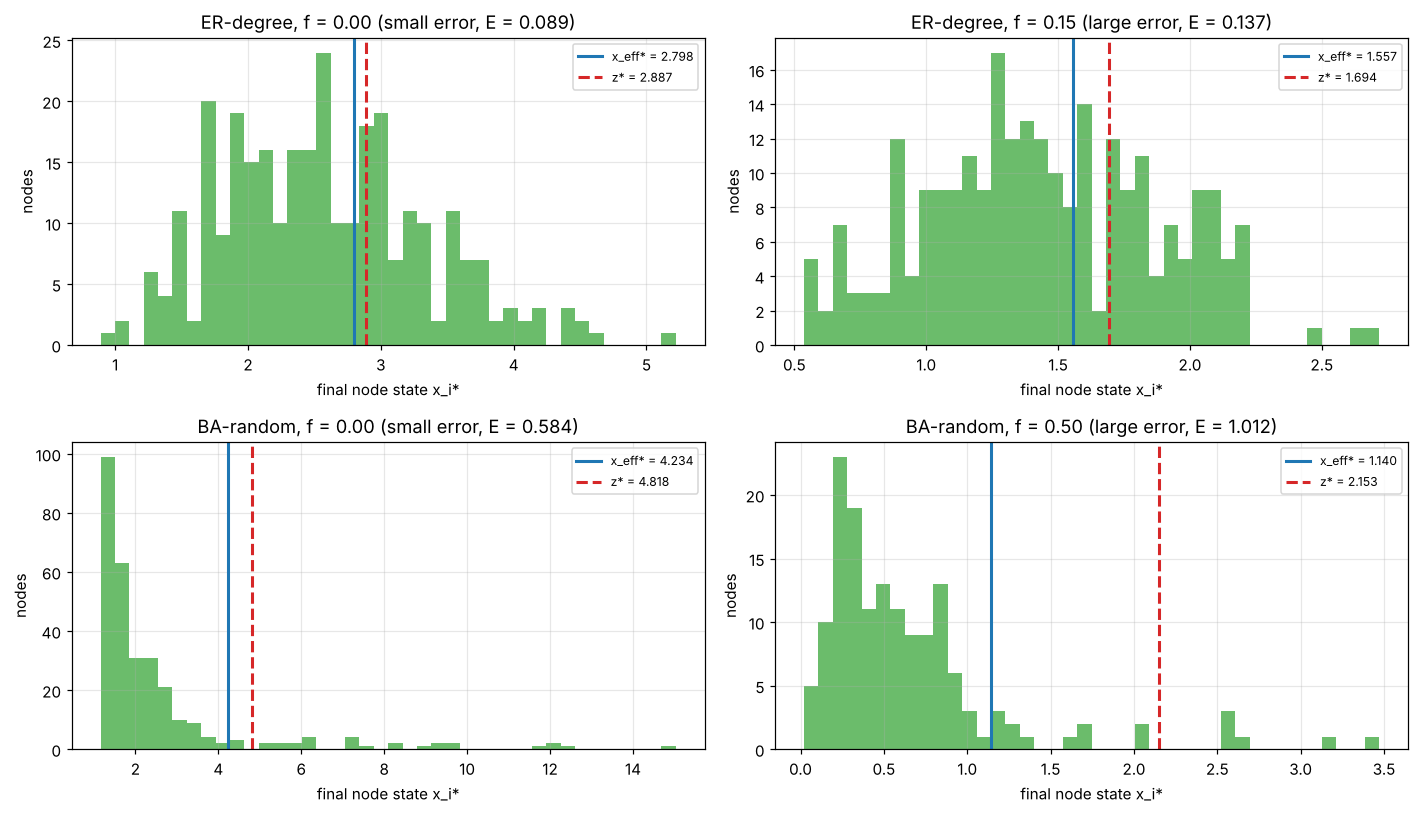

In [13]:
# Distribution of final node states at a small-error and a large-error removal fraction (x0 = 5).
# Both fractions are chosen among those where the full network is still active (x_eff* > 1e-3), so the
# histogram shows the spread of states; the collapsed fractions (all x_i = 0) are discussed in the text.
fig, axes = plt.subplots(2, 2, figsize=(13, 7.5))
for i, name in enumerate(NETS):
    E_best = None
    for strat in ("degree", "random"):
        xe = series(GENE, name, strat, 5.0, "xeff", F_COARSE); zz = series(GENE, name, strat, 5.0, "z", F_COARSE)
        E = np.abs(xe - zz)
        if E_best is None or np.nanmax(E) > np.nanmax(E_best[2]): E_best = (strat, xe, E)
    strat, xe, E = E_best
    act = np.where(xe > ACTIVE)[0]
    f_small = F_COARSE[act[np.argmin(E[act])]]; f_large = F_COARSE[act[np.argmax(E[act])]]
    for j, (f, lab) in enumerate(((f_small, "small error"), (f_large, "large error"))):
        r = GENE[(name, strat, f, 5.0)]; ax = axes[i, j]
        ax.hist(r["x_final"], bins=40, color="C2", alpha=0.7)
        ax.axvline(r["xeff"], color="C0", lw=2, label=f"x_eff* = {r['xeff']:.3f}")
        ax.axvline(r["z"], color="C3", ls="--", lw=2, label=f"z* = {r['z']:.3f}")
        ax.set(xlabel="final node state x_i*", ylabel="nodes",
               title=f"{name}-{strat}, f = {f:.2f} ({lab}, E = {abs(r['xeff']-r['z']):.3f})")
        ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Observations (d).** From $x(0)=0.01$ both models go to $0$, so $E_{\rm abs}\approx0$. From $x(0)=5$ the
error is moderate far from the transition (ER $\sim0.1$, BA $\sim0.5$). It peaks in the window between the
full-network collapse and the reduced-model collapse, where the full network is inactive and $z^*\approx1$–$1.4$
is still active: ER-degree max $1.24$ at $f=0.20$, BA-random max $1.41$ at $f=0.55$. For BA-degree that
window ($0.07\le f<0.09$) falls between coarse grid points, so its largest coarse-grid error is already at
$f=0$ (0.58, from heterogeneity). BA errors exceed ER errors throughout the active regime.
The histograms show why. Both fractions are taken from the still-active regime. For ER-degree, $f=0$
($E=0.089$) and $f=0.15$ ($E=0.137$) both give a fairly compact, unimodal spread of states. For BA-random,
$f=0$ ($E=0.58$) is already right-skewed because hubs reach $x_i\approx15$. At $f=0.50$ ($E=1.01$), just before
the collapse, most low-degree nodes sit close to $0$ while a few hubs stay high. $x^*_{\rm eff}=1.14$ is then a
poor summary of a partially active network, and $z^*=2.15$ overestimates it by almost a factor of two. At
the collapsed fractions with the largest errors (ER-degree $f=0.20$, BA-random $f=0.55$) every node is at 0
while $z^*$ is still on the positive branch.

---
## Q3. SIS dynamics and persistence under network damage

$$\dot x_i=-\mu x_i+\lambda(1-x_i)\sum_jA_{ij}x_j,\qquad \dot z=-\mu z+\lambda\beta(1-z)z,$$
$\mu=1,\ \lambda=0.15,\ x_i(0)=z(0)=0.05$. Jacobian: $J=-\mu I+\lambda\big[\mathrm{diag}(1-x)A-\mathrm{diag}(Ax)\big]$.
The reduced model has $z^*=0$ for $\lambda\beta\le\mu$ and $z^*=1-\mu/(\lambda\beta)$ otherwise (transcritical
bifurcation at $\beta=\mu/\lambda=6.667$). Linearising the full model at $x=0$ gives
$\dot x=(-\mu I+\lambda A)x$, so the disease-free state of the full model loses stability at $\lambda\Lambda_{\max}=\mu$.

In [14]:
MU, LAM, X0_SIS, EXT = 1.0, 0.15, 0.05, 1e-6
RECHECK_LOG = []

def sis_full(A):
    rhs = lambda t, x: -MU * x + LAM * (1 - x) * (A @ x)
    jac = lambda t, x: -MU * np.eye(len(x)) + LAM * ((1 - x)[:, None] * A - np.diag(A @ x))
    return rhs, jac

def sis_reduced(beta):
    rhs = lambda t, z: -MU * z + LAM * beta * (1 - z) * z
    jac = lambda t, z: np.array([[-MU + LAM * beta * (1 - 2 * z[0])]])
    return rhs, jac

def run_sis(A, keep_traj=False, t_first=T_FIRST, t_max=T_MAX):
    rhs, jac = sis_full(A)
    full = integrate_to_steady(rhs, jac, np.full(A.shape[0], X0_SIS), keep_traj, t_first, t_max)
    b = beta_of(A)
    rec = dict(beta=b, Lmax=np.linalg.eigvalsh(A)[-1] if A.size else 0.0, x_final=full["y"],
               xeff=x_eff(A, full["y"]), full_conv=full["converged"], full_res=full["residual"], full_T=full["t_end"])
    if np.isfinite(rec["xeff"]) and 1e-8 <= rec["xeff"] <= 1e-4:
        # borderline classification: repeat with a 10x longer first interval and a tighter residual tolerance
        long = integrate_to_steady(rhs, jac, np.full(A.shape[0], X0_SIS), False, 10 * full["t_end"], 100 * T_MAX, 1e-10)
        new = x_eff(A, long["y"])
        RECHECK_LOG.append(("full", b, rec["xeff"], new, long["t_end"]))
        rec.update(x_final=long["y"], xeff=new, full_T=long["t_end"], full_res=long["residual"])
    if np.isnan(b):
        rec.update(z=np.nan, red_conv=True, red_res=0.0, red_T=0.0); return rec, full, None
    rr, rj = sis_reduced(b)
    red = integrate_to_steady(rr, rj, [X0_SIS], keep_traj, t_first, t_max)
    rec.update(z=red["y"][0], red_conv=red["converged"], red_res=red["residual"], red_T=red["t_end"])
    if 1e-8 <= rec["z"] <= 1e-4:
        long = integrate_to_steady(rr, rj, [X0_SIS], False, 10 * red["t_end"], 100 * T_MAX, 1e-10)
        RECHECK_LOG.append(("reduced", b, rec["z"], long["y"][0], long["t_end"]))
        rec.update(z=long["y"][0], red_T=long["t_end"], red_res=long["residual"])
    return rec, full, red

def print_rechecks():
    print("Borderline runs (final level in [1e-8, 1e-4]) re-integrated 10x longer with residual tol 1e-10:")
    if not RECHECK_LOG: print("  none"); return
    for m, b, old, new, T in RECHECK_LOG:
        cls = lambda v: "extinct" if v < EXT else "persist"
        print(f"  {m:7s} beta={b:7.3f}: {old:.3e} ({cls(old)}) -> {new:.3e} ({cls(new)}) at t={T:.0f}")
    RECHECK_LOG.clear()

### Q3(a) Undamaged networks

net     beta     x_eff*         z*   z* exact     |err|  T_full   res_full  T_red    res_red
ER    12.932   0.465202   0.484494   0.484494  1.93e-02     300   2.22e-16    300   5.55e-17


BA    20.101   0.536522   0.668345   0.668345  1.32e-01     300   1.22e-15    300   0.00e+00


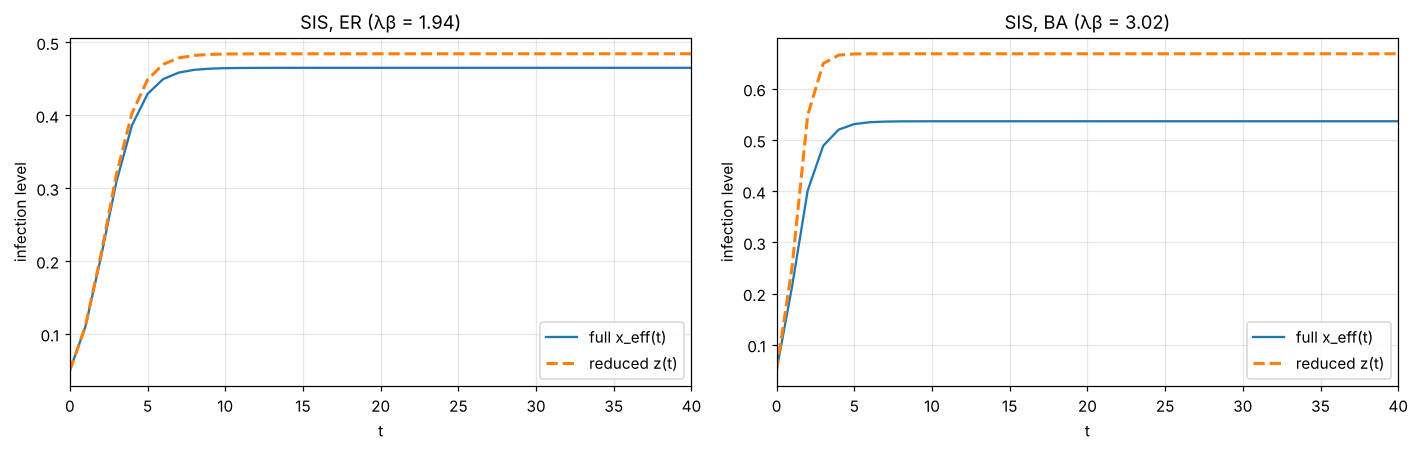

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
print(f"{'net':4s}{'beta':>8s}{'x_eff*':>11s}{'z*':>11s}{'z* exact':>11s}{'|err|':>10s}"
      f"{'T_full':>8s}{'res_full':>11s}{'T_red':>7s}{'res_red':>11s}")
for ax, (name, A) in zip(axes, NETS.items()):
    k = A.sum(1)
    rec, full, red = run_sis(A, keep_traj=True)
    ax.plot(full["t"], k @ full["Y"] / k.sum(), label="full x_eff(t)")
    ax.plot(red["t"], red["Y"][0], "--", lw=2, label="reduced z(t)")
    ax.set(xlabel="t", ylabel="infection level", title=f"SIS, {name} (λβ = {LAM*rec['beta']:.2f})", xlim=(0, 40))
    ax.legend()
    print(f"{name:4s}{rec['beta']:8.3f}{rec['xeff']:11.6f}{rec['z']:11.6f}{1-MU/(LAM*rec['beta']):11.6f}"
          f"{abs(rec['xeff']-rec['z']):10.2e}{rec['full_T']:8.0f}{rec['full_res']:11.2e}{rec['red_T']:7.0f}{rec['red_res']:11.2e}"
          f"{'' if rec['full_conv'] and rec['red_conv'] else '   <-- NOT CONVERGED'}")
plt.tight_layout(); plt.show()

**Observations (a).** Both undamaged networks are above threshold (ER $\lambda\beta=1.94$, BA $3.02$), so the
infection persists in both models. ER: $x^*_{\rm eff}=0.4652$ vs $z^*=0.4845$ ($E=0.019$). BA: $0.5365$ vs
$0.6683$ ($E=0.132$). The simulated $z^*$ equals the analytic $1-\mu/(\lambda\beta)$ to all digits shown. The
reduced model overestimates the prevalence, much more for BA. There hubs are almost always infected, so
the saturation factor $(1-x_i)$ cuts their contribution, which the closure
$L((1-x)Ax)\approx(1-z)\beta z$ misses. All runs met the $10^{-8}$ residual within $[0,300]$.

### Q3(b) Node-removal experiment

In [16]:
def sis_experiment(f_values):
    res = {}
    for name, A in NETS.items():
        for strat in ("degree", "random"):
            order = removal_order(A, strat)
            for f in f_values:
                res[(name, strat, f)] = run_sis(damaged(A, order, f))[0]
    return res

t0 = time.time()
SIS = sis_experiment(F_COARSE)
print(f"{len(SIS)} runs in {time.time()-t0:.1f} s")
nc = [(k, v["full_res"], v["red_res"]) for k, v in SIS.items() if not (v["full_conv"] and v["red_conv"])]
print("Runs not meeting the tolerance:", nc if nc else "none")
omitted = [k for k, v in SIS.items() if np.isnan(v["beta"])]
print("Cases with no edges (omitted from comparison):", omitted if omitted else "none")

print_rechecks()

68 runs in 4.4 s
Runs not meeting the tolerance: none
Cases with no edges (omitted from comparison): [('BA', 'degree', np.float64(0.8))]
Borderline runs (final level in [1e-8, 1e-4]) re-integrated 10x longer with residual tol 1e-10:
  full    beta=  6.154: 6.706e-08 (extinct) -> -3.811e-20 (extinct) at t=3000


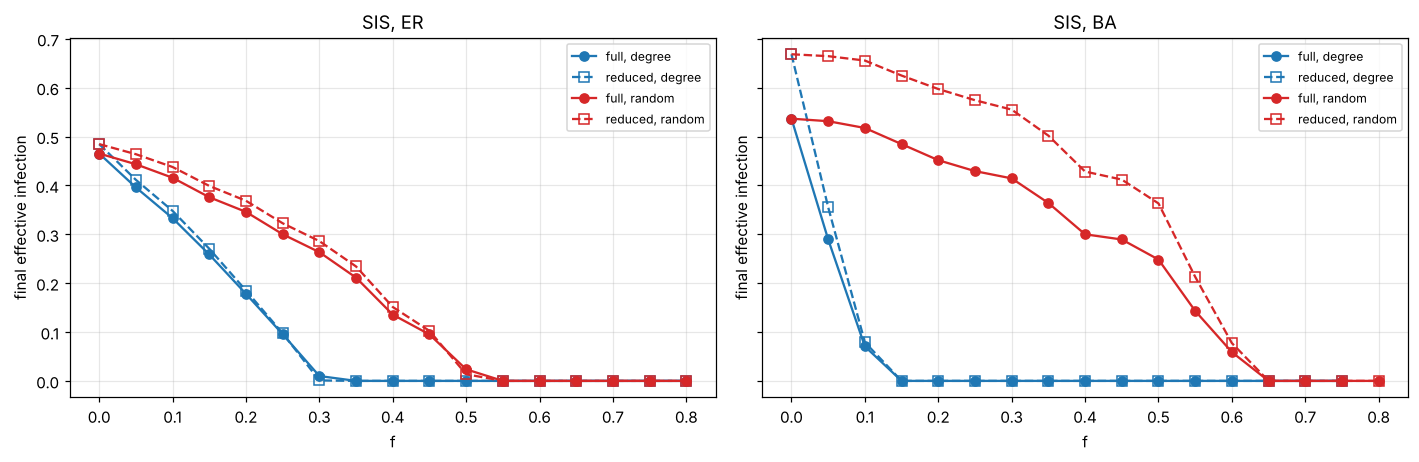

Classification (E = extinction, final level < 1e-6; P = persistence):
                      0.00 0.05 0.10 0.15 0.20 0.25 0.30 0.35 0.40 0.45 0.50 0.55 0.60 0.65 0.70 0.75 0.80
ER-degree full       P    P    P    P    P    P    P    E    E    E    E    E    E    E    E    E    E 
ER-degree red        P    P    P    P    P    P    P    E    E    E    E    E    E    E    E    E    E 
ER-random full       P    P    P    P    P    P    P    P    P    P    P    E    E    E    E    E    E 
ER-random red        P    P    P    P    P    P    P    P    P    P    P    E    E    E    E    E    E 
BA-degree full       P    P    P    E    E    E    E    E    E    E    E    E    E    E    E    E    - 
BA-degree red        P    P    P    E    E    E    E    E    E    E    E    E    E    E    E    E    - 
BA-random full       P    P    P    P    P    P    P    P    P    P    P    P    P    E    E    E    E 
BA-random red        P    P    P    P    P    P    P    P    P    P    P    P    P    E    E   

In [17]:
def sseries(DB, name, strat, key, fvals):
    return np.array([DB[(name, strat, f)][key] for f in fvals])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), sharey=True)
for ax, name in zip(axes, NETS):
    for c, strat in zip(("C0", "C3"), ("degree", "random")):
        ax.plot(F_COARSE, sseries(SIS, name, strat, "xeff", F_COARSE), "o-", color=c, label=f"full, {strat}")
        ax.plot(F_COARSE, sseries(SIS, name, strat, "z", F_COARSE), "s--", color=c, mfc="none", label=f"reduced, {strat}")
    ax.set(xlabel="f", ylabel="final effective infection", title=f"SIS, {name}"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

print("Classification (E = extinction, final level < 1e-6; P = persistence):")
print(" " * 22 + " ".join(f"{f:4.2f}" for f in F_COARSE))
for name in NETS:
    for strat in ("degree", "random"):
        for key, lab in (("xeff", "full"), ("z", "red ")):
            v = sseries(SIS, name, strat, key, F_COARSE)
            print(f"{name}-{strat:6s} {lab}     " + " ".join("  - " if np.isnan(x) else ("  E " if x < EXT else "  P ") for x in v))
print("('-' = no edges remain: effective quantities undefined, omitted)")

**Observations (b).** Extinction (coarse grid) starts at $f=0.35$ (ER-degree), $0.55$ (ER-random), $0.15$
(BA-degree) and $0.65$ (BA-random). The full and reduced classifications agree at every coarse fraction.
Degree-targeted removal is far more effective, especially for BA. For BA-degree at $f=0.80$ no edges
remain, so the effective quantities are undefined and the case is omitted. Near the threshold the decay is
slow (critical slowing down). Borderline levels in $[10^{-8},10^{-4}]$ were therefore re-integrated with a
10× longer interval and a tighter residual tolerance; the log lists them. One refined-grid run
(ER-random, $f=0.52$) switched from 'persist' ($1.2\times10^{-6}$) to 'extinct' after the longer
integration. No coarse-grid classification changed.

### Q3(c) Thresholds: $\lambda\beta=\mu$ vs $\lambda\Lambda_{\max}=\mu$

$\beta$ and $\Lambda_{\max}$ are computed on the fine 0.01 grid. The full SIS model is then simulated on a
0.01 grid in a window around the coarse transition and around both crossings.

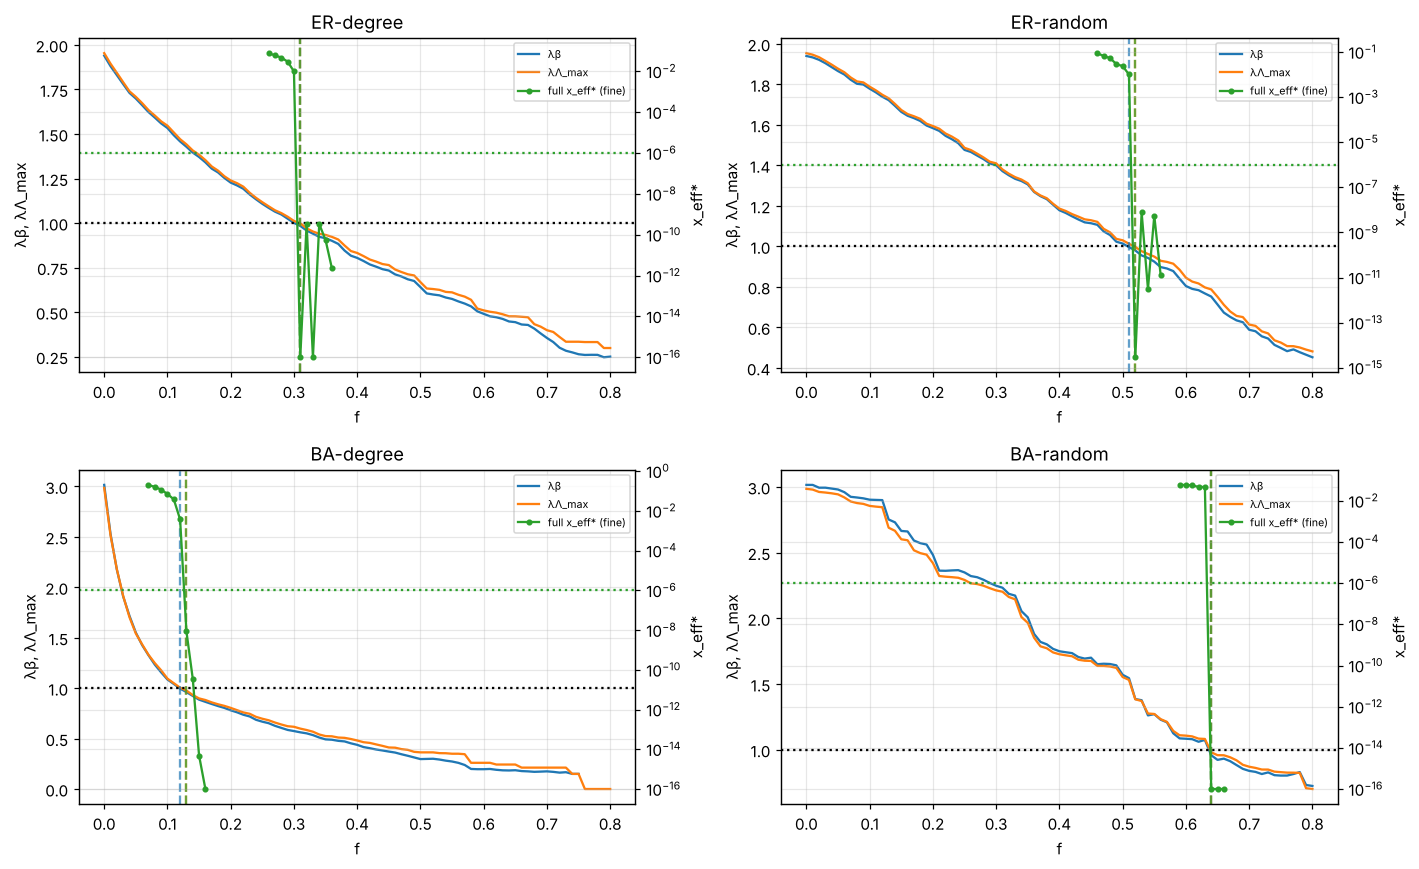

Borderline runs (final level in [1e-8, 1e-4]) re-integrated 10x longer with residual tol 1e-10:
  full    beta=  6.559: 4.661e-07 (extinct) -> 1.791e-17 (extinct) at t=48000
  reduced beta=  6.387: 8.119e-08 (extinct) -> -1.216e-17 (extinct) at t=3000
  full    beta=  6.269: 1.427e-08 (extinct) -> -1.884e-21 (extinct) at t=3000
  reduced beta=  6.643: 5.650e-07 (extinct) -> -4.233e-18 (extinct) at t=24000
  full    beta=  6.530: 1.231e-06 (persist) -> 2.916e-15 (extinct) at t=24000
  reduced beta=  6.530: 6.821e-08 (extinct) -> 1.601e-17 (extinct) at t=6000
  reduced beta=  6.368: 3.476e-08 (extinct) -> -2.191e-18 (extinct) at t=3000
  reduced beta=  6.632: 1.984e-08 (extinct) -> 1.492e-17 (extinct) at t=24000
  reduced beta=  6.410: 2.166e-07 (extinct) -> 2.477e-17 (extinct) at t=3000
  full    beta=  6.390: 7.973e-08 (extinct) -> 2.040e-17 (extinct) at t=6000
  reduced beta=  6.390: 8.991e-08 (extinct) -> -9.561e-20 (extinct) at t=3000
  full    beta=  6.154: 6.706e-08 (extinct) -> -

In [18]:
def first_below(fvals, vals, thr):
    idx = np.where(~(vals > thr))[0]
    return fvals[idx[0]] if len(idx) else None

fine_sis, rows = {}, []
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for i, (name, A) in enumerate(NETS.items()):
    for j, strat in enumerate(("degree", "random")):
        order = removal_order(A, strat)
        subs = [damaged(A, order, f) for f in F_FINE]
        betas = np.array([beta_of(S) for S in subs])
        lmax = np.array([np.linalg.eigvalsh(S)[-1] for S in subs])
        f_beta = first_below(F_FINE, LAM * betas, MU)
        f_lam = first_below(F_FINE, LAM * lmax, MU)
        f_obs_c = first_below(F_COARSE, sseries(SIS, name, strat, "xeff", F_COARSE), EXT)
        cands = [x for x in (f_beta, f_lam, f_obs_c) if x is not None]
        lo_w, hi_w = (min(cands) - 0.05, max(cands) + 0.01) if cands else (0.75, 0.80)
        fw = F_FINE[(F_FINE >= lo_w - 1e-9) & (F_FINE <= hi_w + 1e-9)]
        recs = {f: run_sis(damaged(A, order, f))[0] for f in fw}
        fine_sis[(name, strat)] = recs
        xw = np.array([recs[f]["xeff"] for f in fw])
        f_obs = first_below(fw, xw, EXT)
        rows.append((name, strat, f_obs_c, f_obs, f_beta, f_lam))
        ax = axes[i, j]; ax2 = ax.twinx()
        ax.plot(F_FINE, LAM * betas, "C0-", label="λβ"); ax.plot(F_FINE, LAM * lmax, "C1-", label="λΛ_max")
        ax.axhline(MU, color="k", ls=":")
        ax2.semilogy(fw, np.maximum(xw, 1e-16), "C2o-", ms=3, label="full x_eff* (fine)")
        ax2.axhline(EXT, color="C2", ls=":")
        for fv, c in ((f_beta, "C0"), (f_lam, "C1"), (f_obs, "C2")):
            if fv is not None: ax.axvline(fv, color=c, ls="--", alpha=0.7)
        ax.set(xlabel="f", ylabel="λβ, λΛ_max", title=f"{name}-{strat}"); ax2.set_ylabel("x_eff*")
        h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
        ax.legend(h1 + h2, l1 + l2, fontsize=7, loc="upper right")
plt.tight_layout(); plt.show()
print_rechecks()

fmt = lambda v: f"{v:.2f}" if v is not None else "  >0.80"
print(f"{'case':14s}{'obs (0.05)':>11s}{'obs (0.01)':>11s}{'λβ=μ':>9s}{'λΛmax=μ':>10s}")
for r in rows:
    print(f"{r[0]+'-'+r[1]:14s}{fmt(r[2]):>11s}{fmt(r[3]):>11s}{fmt(r[4]):>9s}{fmt(r[5]):>10s}")

**Observations (c).** On the 0.01 grid the full model's observed extinction fraction equals the spectral
crossing $\lambda\Lambda_{\max}=\mu$ **in all four cases** (0.31, 0.52, 0.13, 0.64). This is expected, because the
stability of the disease-free state of the full model is set exactly by $\lambda\Lambda_{\max}-\mu$. The
reduced-model crossing $\lambda\beta=\mu$ agrees for ER-degree and BA-random, but comes 0.01 too early for
ER-random (0.51) and BA-degree (0.12). In the damaged networks $\Lambda_{\max}>\beta$ (for example ER-random
at $f=0.51$: $\beta=6.64<\mu/\lambda=6.67<\Lambda_{\max}=6.75$), so the 1D model predicts extinction while the
network still sustains an endemic state. The $\lambda\Lambda_{\max}$ crossing tracks the numerical transition more closely.

### Q3(d) Error $E_{\rm abs}=|x^*_{\rm eff}-z^*|$

case             max E_abs   at f
ER-degree       1.9292e-02   0.00
ER-random       2.3134e-02   0.15
BA-degree       1.3182e-01   0.00
BA-random       1.4561e-01   0.20


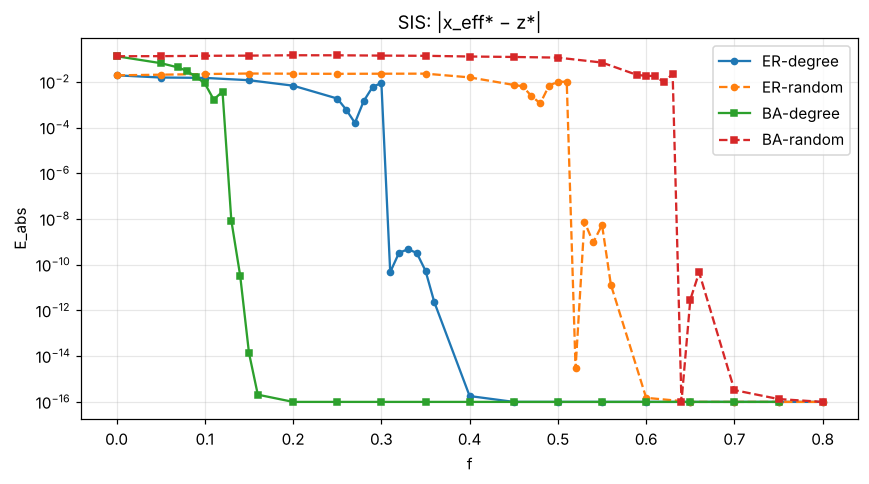

In [19]:
fig, ax = plt.subplots(figsize=(8, 4.5))
print(f"{'case':14s}{'max E_abs':>12s}{'at f':>7s}")
for name, mk in (("ER", "o"), ("BA", "s")):
    for strat, ls in (("degree", "-"), ("random", "--")):
        # merge coarse and refined results
        allr = {f: SIS[(name, strat, f)] for f in F_COARSE}
        allr.update(fine_sis[(name, strat)])
        fs = np.array(sorted(allr))
        E = np.array([abs(allr[f]["xeff"] - allr[f]["z"]) for f in fs])
        ax.semilogy(fs, np.maximum(E, 1e-16), mk + ls, ms=4, label=f"{name}-{strat}")
        i = np.nanargmax(E)
        print(f"{name+'-'+strat:14s}{E[i]:12.4e}{fs[i]:7.2f}")
ax.set(xlabel="f", ylabel="E_abs", title="SIS: |x_eff* − z*|"); ax.legend()
plt.tight_layout(); plt.show()

In [20]:
# Behaviour near the transition: relative error and classification mismatches on the refined grid
for (name, strat), recs in fine_sis.items():
    print(f"{name}-{strat}:")
    print(f"   {'f':>5s}{'β':>8s}{'Λmax':>8s}{'x_eff*':>12s}{'z*':>12s}{'E_abs':>11s}{'E_rel':>9s}  class(full/red)")
    for f in sorted(recs):
        r = recs[f]
        if np.isnan(r["beta"]): continue
        rel = abs(r["xeff"] - r["z"]) / max(r["xeff"], r["z"], 1e-300) if max(r["xeff"], r["z"]) >= EXT else 0.0
        c = lambda v: "E" if v < EXT else "P"
        flag = "  <-- mismatch" if c(r["xeff"]) != c(r["z"]) else ""
        print(f"   {f:5.2f}{r['beta']:8.3f}{r['Lmax']:8.3f}{r['xeff']:12.3e}{r['z']:12.3e}"
              f"{abs(r['xeff']-r['z']):11.2e}{rel:9.2f}  {c(r['xeff'])}/{c(r['z'])}{flag}")

ER-degree:
       f       β    Λmax      x_eff*          z*      E_abs    E_rel  class(full/red)
    0.26   7.234   7.293   7.782e-02   7.844e-02   6.16e-04     0.01  P/P
    0.27   7.093   7.144   6.023e-02   6.007e-02   1.61e-04     0.00  P/P
    0.28   6.987   7.039   4.728e-02   4.583e-02   1.45e-03     0.03  P/P
    0.29   6.830   6.904   2.987e-02   2.392e-02   5.94e-03     0.20  P/P
    0.30   6.673   6.745   9.927e-03   9.569e-04   8.97e-03     0.90  P/P
    0.31   6.559   6.656   1.791e-17   4.746e-11   4.75e-11     0.00  E/E
    0.32   6.387   6.470   3.322e-10  -1.216e-17   3.32e-10     0.00  E/E
    0.33   6.269   6.350  -1.884e-21   4.735e-10   4.74e-10     0.00  E/E
    0.34   6.149   6.264   3.343e-10   2.409e-12   3.32e-10     0.00  E/E
    0.35   6.099   6.223   5.468e-11   2.888e-13   5.44e-11     0.00  E/E
    0.36   6.002   6.149   2.276e-12  -1.170e-14   2.29e-12     0.00  E/E
ER-random:
       f       β    Λmax      x_eff*          z*      E_abs    E_rel  class(fu

**Observations (d).** Largest observed errors: ER-degree $0.0193$ at $f=0$, ER-random $0.0231$ at $f=0.15$,
BA-degree $0.132$ at $f=0$, BA-random $0.146$ at $f=0.20$. The absolute error is largest *far* from extinction,
where prevalence is high and node states are most heterogeneous. Near the transition $E_{\rm abs}$ shrinks
only because both levels go to zero. The relative error there grows to $\approx0.2$–$1.0$ (refined table),
and at ER-random $f=0.51$ and BA-degree $f=0.12$ the two models disagree qualitatively: full persists,
reduced is extinct. **Agreement far from extinction therefore does not guarantee agreement near the
transition.** The threshold is set by $\Lambda_{\max}$, a spectral property that the degree-based $\beta$ only
approximates. Also, a tiny absolute error near criticality hides a large relative and qualitative error.
In the fully extinct regime both models give 0 and the error vanishes.